In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Read normal vectors to basal plane for the grains of interest:
#### 1- In Paraview, click in the corresponding grain and read voxel info "normal_vector_to_basal_plane" 
#### 2- Insert below the result with the format [Y, -Z, X]

In [2]:
OR_vector= {
    'Hydride 1-p1': [-0.535, -0.864, 0.243],
    'Hydride 1-p2': [-0.535, -0.864, 0.243],
    'Hydride 2-p1': [-0.074, -0.630, -0.773],
    'Hydride 2-p2': [-0.074, -0.630, -0.773],
    'Hydride 3': [-0.257, 0.515, -0.129],
    'Hydride 4-p1':[-0.257, 0.515, -0.129],
    'Hydride 4-p2':[-0.257, 0.515, -0.129],
    'Hydride 5-p1':[-0.278, -0.555, -0.278],
    'Hydride 5-p2':[-0.278, -0.555, -0.278],
    'Hydride 6':[-0.281, 0.952, -0.073],
    'Hydride 7':[-0.358, 0.963, 0.178],
    'Hydride 8':[-0.005, -0.251, -0.997],
    'Hydride 9':[-0.206, 0.337, 0.963],
    'Hydride 10':[-0.448, 0.533, 0.595]
}

In [3]:
NoOR_vector= {
    'Hydride 1-p1':[-0.448, 0.533, 0.595],
    'Hydride 1-p2':[-0.448, 0.533, 0.595],
    'Hydride 2-p1': [-0.257, 0.515, -0.129],
    'Hydride 2-p2': [-0.257, 0.515, -0.129],
    'Hydride 3': [-0.497, -0.747, -0.495],
    'Hydride 4-p1': [-0.278, -0.555, -0.278],
    'Hydride 4-p2': [-0.278, -0.555, -0.278],
    'Hydride 5-p1': [-0.358, 0.963, 0.178],
    'Hydride 5-p2': [-0.358, 0.963, 0.178],
    'Hydride 6':[-0.358, 0.963, 0.178],
    'Hydride 7':[-0.281, 0.952, -0.073],
    'Hydride 8':[-0.357, 0.963, 0.178],
    'Hydride 9':[-0.410, 0.623, 0.536],
    'Hydride 10':[-0.410, 0.623, 0.536]
}

In [4]:
normal_vector= {
    'Hydride 1-p1': [0.950, 0.175, 0.258],
    'Hydride 1-p2': [0.984, 0.016, 0.176],
    'Hydride 2-p1': [-0.661, -0.113, 0.741],
    'Hydride 2-p2': [-0.526, -0.496, 0.691],
    'Hydride 3':[0.456, -0.872, 0.182],
    'Hydride 4-p1':[0.679, 0.732, -0.057],
    'Hydride 4-p2':[0.380, 0.899, -0.219],
    'Hydride 5-p1':[0.249, -0.954, -0.169],
    'Hydride 5-p2':[0.178, -0.961, -0.212],
    'Hydride 6':[-0.365,0.037,0.930],
    'Hydride 7':[-0.019, 0.118, 0.993],
    'Hydride 8':[0.706, 0.113, 0.699],
    'Hydride 9':[0.411, 0.165, 0.897 ],
    'Hydride 10':[0.091, 0.646, -0.758]
}

In [5]:
def angle(n, b): # θ=arctan2(∥n×b∥,|n⋅b|)
    dot = np.dot(n, b)
    normcross = np.linalg.norm(np.cross(n, b))
    dot = abs(dot)  # make angle insensitive to sign flips
    # Use atan2 for better numerical stability than arccos
    return np.degrees(np.arctan2(normcross, dot))

In [6]:
angles_OR = {}
angles_NoOR = {}

for h in normal_vector:
    angles_OR[h] = int(np.round(angle(OR_vector[h], normal_vector[h])))
    angles_NoOR[h] = int(np.round(angle(NoOR_vector[h], normal_vector[h])))


In [7]:
angles_OR

{'Hydride 1-p1': 55,
 'Hydride 1-p2': 62,
 'Hydride 2-p1': 63,
 'Hydride 2-p2': 79,
 'Hydride 3': 2,
 'Hydride 4-p1': 69,
 'Hydride 4-p2': 48,
 'Hydride 5-p1': 42,
 'Hydride 5-p2': 37,
 'Hydride 6': 86,
 'Hydride 7': 73,
 'Hydride 8': 45,
 'Hydride 9': 37,
 'Hydride 10': 81}

In [8]:
angles_NoOR

{'Hydride 1-p1': 79,
 'Hydride 1-p2': 69,
 'Hydride 2-p1': 88,
 'Hydride 2-p2': 69,
 'Hydride 3': 71,
 'Hydride 4-p1': 32,
 'Hydride 4-p2': 37,
 'Hydride 5-p1': 6,
 'Hydride 5-p2': 10,
 'Hydride 6': 71,
 'Hydride 7': 87,
 'Hydride 8': 89,
 'Hydride 9': 63,
 'Hydride 10': 87}

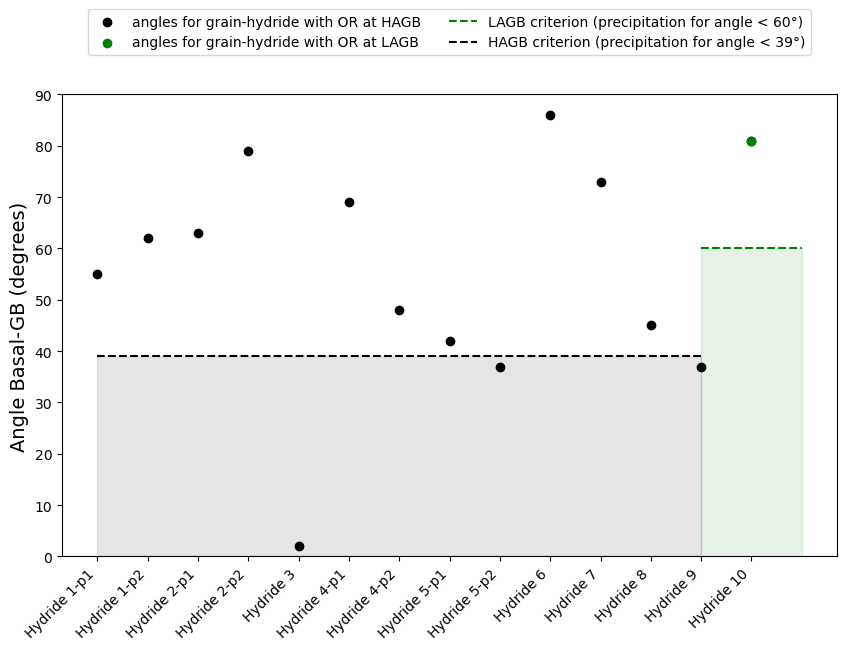

In [10]:
labels = list(angles_OR.keys())
values = list(angles_OR.values())
values_NoOR = list(angles_NoOR.values())


plt.figure(figsize=(10,6))
plt.scatter(labels, values, color='black', label='angles for grain-hydride with OR at HAGB')
plt.scatter(labels[-1], values[-1], color='green',label='angles for grain-hydride with OR at LAGB') # only the last hydride was at LAGB
#plt.scatter(labels, values_NoOR, color='grey', label='angles for grain-hydride without OR at HAGB')
#plt.scatter(labels[-1], values_NoOR[-1], color='lightgreen',label='angles for grain-hydride without OR at LAGB') # only the last hydride was at LAGB

plt.hlines(y=60, xmin=12, xmax=14, color='green', linestyle='--', label='LAGB criterion (precipitation for angle < 60°)')
plt.hlines(y=39, xmin=0, xmax=len(labels)-2, color='black', linestyle='--', label='HAGB criterion (precipitation for angle < 39°)')
plt.fill_between(range(12,15), 0, 60, color='green', alpha=0.1)
plt.fill_between(range(len(labels)-1), 0, 39, color='black', alpha=0.1)
plt.ylim(0, 90)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Angle Basal-GB (degrees)', fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.20), ncol=2)


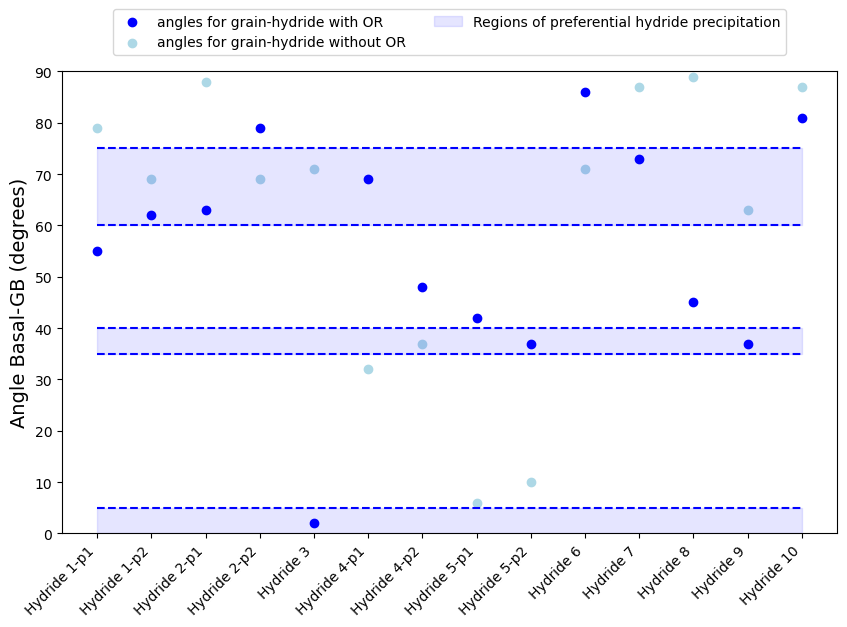

In [12]:
labels = list(angles_OR.keys())
values = list(angles_OR.values())
values_NoOR = list(angles_NoOR.values())    

plt.figure(figsize=(10,6))
plt.scatter(labels, values, color='blue', label='angles for grain-hydride with OR')
plt.scatter(labels, values_NoOR, color='lightblue', label='angles for grain-hydride without OR')

plt.hlines(y=75, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')
plt.hlines(y=60, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')
plt.hlines(y=40, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')
plt.hlines(y=35, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--' )
plt.hlines(y=5, xmin=0, xmax=len(labels)-1, color='blue', linestyle='--')


plt.fill_between(range(len(labels)), 60, 75, color='blue', alpha=0.1, label='Regions of preferential hydride precipitation')
plt.fill_between(range(len(labels)), 35, 40, color='blue', alpha=0.1)
plt.fill_between(range(len(labels)), 0, 5, color='blue', alpha=0.1)

plt.ylim(0, 90)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Angle Basal-GB (degrees)', fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=2)
